# Влияние соперников на обучение агента Pokémon

## Цель и гипотеза

Тема работы — обучение с подкреплением. Агент учится выбирать атаки и замены в Pokémon Showdown первого поколения. Задача связана с принятием решений при неполной информации и переносом стратегии на новых соперников.

Сравниваются два режима: `single` — обучение против соперника, который выбирает самые мощные атаки; `mixture` — обучение против смеси этого соперника и случайного игрока. Гипотеза: разнообразие соперников улучшит результат против новой эвристической стратегии.

Для команд используется внешний датасет Metamon Teams. Опыт для обучения агент получает самостоятельно в симуляторе. По сохранённым результатам гипотеза не подтвердилась: против нового соперника получено 8,0% побед у `single` и 6,7% у `mixture`.


## 1. Установка библиотек

Используются poke-env 0.16.1, PyTorch и локальный симулятор Pokémon Showdown. Версии симулятора и датасета закреплены в настройках.


In [ ]:
import subprocess
import sys
import shutil

subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                'poke-env==0.16.1', 'torch', 'pandas', 'matplotlib'], check=True)
if shutil.which('node') is None or shutil.which('npm') is None:
    subprocess.run(['apt-get', 'update', '-qq'], check=True)
    subprocess.run(['apt-get', 'install', '-y', '-qq', 'nodejs', 'npm'], check=True)
print(subprocess.check_output(['node', '--version'], text=True).strip())


v22.23.4


## 2. Импорт библиотек

Подключаются библиотеки для симуляции боёв, обучения сети, работы с данными и построения графиков.


In [ ]:
import copy
import hashlib
import json
import logging
import os
import random
import signal
import socket
import subprocess
import tarfile
import time
from collections import deque
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
import torch.nn as nn
from gymnasium.spaces import Box
from poke_env.battle import MoveCategory, PokemonType, Status
from poke_env.data import GenData, to_id_str
from poke_env.environment import SingleAgentWrapper, SinglesEnv
from poke_env.player import MaxBasePowerPlayer, RandomPlayer, SimpleHeuristicsPlayer
from poke_env.teambuilder import Teambuilder


from IPython.display import display, HTML


## 3. План эксперимента

Каждый режим обучается с тремя начальными значениями seed: 42, 43 и 44. Бюджет — 100 000 решений на агента. Затем каждый агент играет по 100 тестовых боёв против трёх типов соперников: всего 1800 боёв.

Один шаг — одно решение агента. В партии допускается до 500 решений. Seed управляет обучением и выбором команд, но случайность самого симулятора полностью не фиксируется.


In [ ]:

RUN_MODE = 'research'
ROOT = Path.cwd()
SIM_DIR = ROOT / 'pokemon-showdown'
OUTPUT_DIR = ROOT / 'pokemon_rl_results'
OUTPUT_DIR.mkdir(exist_ok=True)
BATTLE_FORMAT = 'gen1ou'
SHOWDOWN_COMMIT = '16db150abae0829180b8721da3bff0e51896a223'
TEAM_REVISION = 'bff785c80a06273faee1c675d368948f5dd65d44'
TEAM_REPO = 'jakegrigsby/metamon-teams'
TEAM_FILE = 'paper_replays/gen1ou.tar.gz'

SETTINGS = {
    'quick': dict(seeds=[42], train_steps=2000, eval_battles=5, warmup=128),
    'research': dict(seeds=[42, 43, 44], train_steps=100000,
                     eval_battles=100, warmup=2000),
}
config = SETTINGS[RUN_MODE]

MAX_DECISIONS = 500
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(2)
print('Режим:', RUN_MODE, 'устройство:', DEVICE, 'настройки:', config)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


Режим: research устройство: cuda настройки: {'seeds': [42, 43, 44], 'train_steps': 100000, 'eval_battles': 100, 'warmup': 2000}


## 4. Запуск симулятора

Сервер Pokémon Showdown работает локально на `127.0.0.1`. Бои проходят против программных соперников. Повторный запуск ячейки останавливает ранее созданный сервер.


In [ ]:

def start_server():
    if not SIM_DIR.exists():
        subprocess.run(['git', 'clone', 'https://github.com/smogon/pokemon-showdown.git',
                        str(SIM_DIR)], check=True)
    current = subprocess.check_output(
        ['git', 'rev-parse', 'HEAD'], cwd=SIM_DIR, text=True).strip()
    if current != SHOWDOWN_COMMIT:
        subprocess.run(['git', 'fetch', 'origin', SHOWDOWN_COMMIT, '--depth', '1'],
                       cwd=SIM_DIR, check=True)
        subprocess.run(['git', 'checkout', '--detach', SHOWDOWN_COMMIT],
                       cwd=SIM_DIR, check=True)
    if not (SIM_DIR / 'node_modules').exists():
        subprocess.run(['npm', 'ci', '--ignore-scripts'], cwd=SIM_DIR, check=True)
    cfg = (SIM_DIR / 'config/config-example.js').read_text()
    cfg += '\nexports.repl = false;\nexports.bindaddress = "127.0.0.1";\n'
    cfg += 'exports.subprocesses = 0;\n'
    (SIM_DIR / 'config/config.js').write_text(cfg)

    with socket.socket() as probe:
        if probe.connect_ex(('127.0.0.1', 8000)) == 0:
            raise RuntimeError('Порт 8000 занят. Остановите прежний сервер или перезапустите сеанс.')
    log_path = OUTPUT_DIR / 'showdown.log'
    with log_path.open('w') as log:
        process = subprocess.Popen(
            ['node', 'pokemon-showdown', 'start', '--no-security', '--port', '8000'],
            cwd=SIM_DIR, stdout=log, stderr=subprocess.STDOUT, start_new_session=True)
    deadline = time.monotonic() + 90
    while time.monotonic() < deadline:
        if process.poll() is not None:
            raise RuntimeError(log_path.read_text()[-6000:])
        try:
            with socket.create_connection(('127.0.0.1', 8000), timeout=1):
                print('Локальный Pokémon Showdown запущен.')
                return process
        except OSError:
            time.sleep(0.5)
    os.killpg(process.pid, signal.SIGTERM)
    raise TimeoutError('Сервер не запустился. Последние сообщения:\n' + log_path.read_text()[-6000:])


def stop_server(process):
    if process is not None and process.poll() is None:
        os.killpg(process.pid, signal.SIGTERM)
        process.wait(timeout=15)


In [ ]:
if 'server_process' in globals():
    stop_server(server_process)
server_process = start_server()


Локальный Pokémon Showdown запущен.


## 5. Датасет и разделение данных

Источник — [Metamon Teams](https://huggingface.co/datasets/jakegrigsby/metamon-teams), архив `paper_replays/gen1ou.tar.gz`. Это восстановленные команды из записей боёв с дополнением скрытых сведений. Датасет задаёт команды для симуляции; действия людей для обучения не используются.

Повторяющиеся команды удаляются по составу и характеристикам, независимо от порядка покемонов и атак. После проверки правил `gen1ou` осталось 2101 уникальная команда. Валидатор не отклонил ни одной из них.

| Выборка | Команд | Назначение |
|---|---:|---|
| Обучающая | 1470 | Сбор опыта и обучение |
| Валидационная | 315 | Отдельная проверка после обучения |
| Тестовая | 316 | Итоговое сравнение |

Команды в выборках не повторяются по используемой подписи, но отдельные виды покемонов могут совпадать. Версия данных и SHA-256 архива сохраняются в отчёте.


In [ ]:

def load_team_dataset():
    data_dir = OUTPUT_DIR / 'data'
    data_dir.mkdir(exist_ok=True)
    archive = data_dir / 'gen1ou_teams.tar.gz'
    url = f'https://huggingface.co/datasets/{TEAM_REPO}/resolve/{TEAM_REVISION}/{TEAM_FILE}'
    if not archive.exists():
        response = requests.get(url, timeout=90)
        response.raise_for_status()
        temporary = archive.with_suffix('.download')
        temporary.write_bytes(response.content)
        temporary.replace(archive)
    sha256 = hashlib.sha256(archive.read_bytes()).hexdigest()
    teams, signatures = [], set()
    with tarfile.open(archive, 'r:gz') as stream:
        for member in stream:
            if not member.isfile() or not member.name.endswith('_team'):
                continue
            text = stream.extractfile(member).read().decode('utf-8').strip()
            mons = Teambuilder.parse_showdown_team(text)
            if len(mons) != 6:
                continue


            canonical = []
            for mon in mons:
                canonical.append((to_id_str(mon.species or mon.nickname or ''),
                                  tuple(sorted(to_id_str(m) for m in mon.moves)),
                                  mon.level or 100, tuple(mon.evs or [0] * 6),
                                  tuple(mon.ivs or [31] * 6)))
            signature = hashlib.sha256(repr(sorted(canonical)).encode()).hexdigest()
            if signature in signatures:
                continue
            signatures.add(signature)
            teams.append(dict(id=signature, source=member.name, text=text,
                              packed=Teambuilder.join_team(mons)))


    validator = '''
const fs = require('fs');
const {Teams, TeamValidator} = require('./dist/sim');
const teams = JSON.parse(fs.readFileSync(0, 'utf8'));
const validator = new TeamValidator('gen1ou');
const valid = teams.map(t => validator.validateTeam(Teams.unpack(t)) === null);
process.stdout.write(JSON.stringify(valid));
'''
    result = subprocess.run(['node', '-e', validator], cwd=SIM_DIR,
                            input=json.dumps([t['packed'] for t in teams]),
                            capture_output=True, text=True, check=True)
    valid = json.loads(result.stdout)
    rejected = len(teams) - sum(valid)
    teams = [team for team, keep in zip(teams, valid) if keep]
    if len(teams) < 30:
        raise RuntimeError(f'Осталось только {len(teams)} допустимых команд. Проверьте архив и правила.')
    rng = np.random.default_rng(2026)
    order = rng.permutation(len(teams))
    teams = [teams[i] for i in order]
    n_train, n_val = int(len(teams) * .7), int(len(teams) * .15)
    pools = dict(train=teams[:n_train], validation=teams[n_train:n_train + n_val],
                 test=teams[n_train + n_val:])
    manifest = dict(repo=TEAM_REPO, revision=TEAM_REVISION, file=TEAM_FILE,
                    archive_sha256=sha256, showdown=SHOWDOWN_COMMIT,
                    rejected_by_validator=rejected,
                    splits={k: [t['id'] for t in v] for k, v in pools.items()})
    (data_dir / 'manifest.json').write_text(json.dumps(manifest, indent=2))
    print('Допустимых уникальных команд:', len(teams), 'отброшено валидатором:', rejected)
    print('Разделение:', {k: len(v) for k, v in pools.items()})
    return pools, manifest


In [ ]:
pools, dataset_manifest = load_team_dataset()


Допустимых уникальных команд: 2101 отброшено валидатором: 0
Разделение: {'train': 1470, 'validation': 315, 'test': 316}


## 6. Анализ данных

В обучающей выборке встречается 58 видов покемонов, в валидационной — 43, в тестовой — 44. График показывает частые виды в обучающих командах. Эти частоты описывают выбранный датасет, а не всех игроков.


In [ ]:
def describe_dataset(pools):
    rows = []
    for split, teams in pools.items():
        for team in teams:
            for mon in Teambuilder.parse_showdown_team(team['text']):
                rows.append(dict(split=split, team_id=team['id'],
                                 species=mon.species or mon.nickname,
                                 n_moves=len(mon.moves)))
    table = pd.DataFrame(rows)
    display(table.head())
    display(table.groupby('split').agg(teams=('team_id', 'nunique'),
                                      pokemon=('species', 'nunique')))
    table[table.split == 'train'].species.value_counts().head(15).plot.bar(
        figsize=(10, 4), title='Частые покемоны в обучающем наборе')
    plt.ylabel('Число включений в команды')
    plt.tight_layout()
    plt.show()
    table.to_csv(OUTPUT_DIR / 'dataset_summary.csv', index=False)


,split,team_id,species,n_moves
0,train,4ac74fbedbb7aa3dfa0fca4eca8d30b7a2ec390fcf6277...,Jynx,4
1,train,4ac74fbedbb7aa3dfa0fca4eca8d30b7a2ec390fcf6277...,Alakazam,4
2,train,4ac74fbedbb7aa3dfa0fca4eca8d30b7a2ec390fcf6277...,Chansey,4
3,train,4ac74fbedbb7aa3dfa0fca4eca8d30b7a2ec390fcf6277...,Exeggutor,4
4,train,4ac74fbedbb7aa3dfa0fca4eca8d30b7a2ec390fcf6277...,Snorlax,4


,teams,pokemon
split,,
test,316,44
train,1470,58
validation,315,43


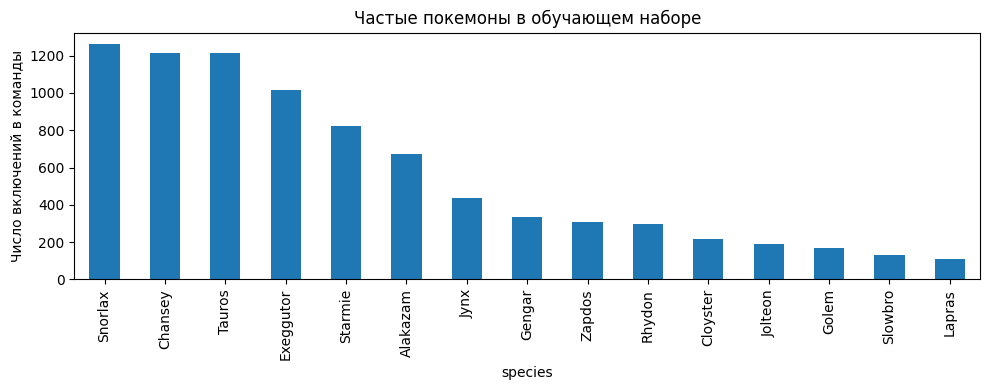

In [ ]:
describe_dataset(pools)


## 7. Состояние боя

На вход сети подаются 1287 признаков: типы и характеристики покемонов, здоровье, статусы, свойства атак и состояние хода. Сведения о противнике берутся только из уже раскрытой информации боя. Отдельная модель истории ходов не используется.


In [ ]:
TYPE_NAMES = [t.name for t in PokemonType if t.value <= 18]
STATUS_NAMES = [s.name for s in Status]
STAT_NAMES = ['hp', 'atk', 'def', 'spa', 'spd', 'spe']
BOOST_NAMES = ['atk', 'def', 'spa', 'spd', 'spe', 'accuracy', 'evasion']
TYPE_CHART = GenData.from_gen(1).type_chart
MOVE_IDS = sorted(name for name, entry in GenData.from_gen(1).moves.items()
                  if 0 < entry.get('num', 0) <= 165) + ['recharge', 'fight']
MON_FEATURES = 1 + 18 + 6 + 1 + 1 + 1 + 7 + 7
MOVE_FEATURES = 1 + 18 + 3 + 6 + len(MOVE_IDS)
N_FEATURES = 12 * MON_FEATURES + 4 * MOVE_FEATURES + 3


def embed_pokemon(mon):
    if mon is None:
        return np.zeros(MON_FEATURES, dtype=np.float32)
    types = {t.name for t in mon.types}
    status = mon.status.name if mon.status else ''
    values = [1.0]
    values += [float(name in types) for name in TYPE_NAMES]
    values += [mon.base_stats.get(name, 0) / 255 for name in STAT_NAMES]
    values += [mon.current_hp_fraction, float(mon.fainted), float(mon.active)]
    values += [float(status == name) for name in STATUS_NAMES]
    values += [mon.boosts.get(name, 0) / 6 for name in BOOST_NAMES]
    return np.asarray(values, dtype=np.float32)


def embedded_moves(battle):

    if battle.active_pokemon is None:
        return []
    moves = list(battle.active_pokemon.moves.values())[:4]
    available = battle.available_moves
    if len(available) == 1 and available[0].id not in [m.id for m in moves]:
        moves = available
    return moves


def embed_battle(battle):
    own = list(battle.team.values())

    opponent = list(battle.opponent_team.values())
    values = []
    for team in [own, opponent]:
        for i in range(6):
            values.extend(embed_pokemon(team[i] if i < len(team) else None))
    moves = embedded_moves(battle)
    target = battle.opponent_active_pokemon
    for i in range(4):
        if i >= len(moves):
            values.extend([0.0] * MOVE_FEATURES)
            continue
        move = moves[i]
        multiplier = 1.0
        if target is not None:
            multiplier = move.type.damage_multiplier(
                target.type_1, target.type_2, type_chart=TYPE_CHART)
        stab = battle.active_pokemon is not None and move.type in battle.active_pokemon.types
        features = [1.0]
        features += [float(move.type.name == name) for name in TYPE_NAMES]
        features += [float(move.category == cat) for cat in
                     [MoveCategory.PHYSICAL, MoveCategory.SPECIAL, MoveCategory.STATUS]]
        features += [min(move.base_power / 250, 4), float(move.accuracy),
                     move.current_pp / max(move.max_pp, 1), move.entry.get("priority", 0) / 7,
                     multiplier / 4, float(stab)]

        features += [float(move.id == name) for name in MOVE_IDS]
        values.extend(features)
    values += [min(battle.turn / 500, 1), float(battle.force_switch), float(battle.wait)]
    state = np.asarray(values, dtype=np.float32)
    assert state.shape == (N_FEATURES,)
    assert np.isfinite(state).all()
    return state


## 8. Действия, награда и соперники

Агент выбирает одно из 10 действий: шесть вариантов замены или четыре атаки. Маска запрещает недоступные действия.

Награда учитывает изменение здоровья, выбывание покемонов и исход боя. Выбывание противника даёт вклад +2, своего покемона — −2; победа — +15, поражение — −15. Главная метрика эксперимента — доля побед, а не накопленная награда.

Соперники: случайный (`random`), выбирающий мощные атаки (`power`) и эвристический (`heuristic`). Последний используется только при итоговой проверке и демонстрации.


In [ ]:
class TeamPool(Teambuilder):
    def __init__(self, records, seed):
        self.records = records
        self.rng = random.Random(seed)

    def yield_team(self):
        return self.rng.choice(self.records)['packed']


class PokemonEnv(SinglesEnv):
    def __init__(self, records, seed, save_replays=False):
        super().__init__(battle_format=BATTLE_FORMAT, team=TeamPool(records, seed),
                         log_level=logging.ERROR, save_replays=save_replays,
                         choose_on_teampreview=False, strict=True)
        self.observation_spaces = {
            agent: Box(-1, 4, shape=(N_FEATURES,), dtype=np.float32)
            for agent in self.possible_agents}

    def embed_battle(self, battle):
        return embed_battle(battle)

    def calc_reward(self, battle):
        return self.reward_computing_helper(battle, fainted_value=2,
                                            hp_value=1, victory_value=15)


OPPONENTS = dict(random=RandomPlayer, power=MaxBasePowerPlayer,
                 heuristic=SimpleHeuristicsPlayer)


class OpponentPool:

    def __init__(self, names, seed):
        self.rng = random.Random(seed)
        self.players = {name: OPPONENTS[name](battle_format=BATTLE_FORMAT,
                       start_listening=False, log_level=logging.ERROR) for name in names}
        self.name = None

    def select(self):
        self.name = self.rng.choice(list(self.players))
        return self.players[self.name]


class BattleEnv(SingleAgentWrapper):
    def __init__(self, records, names, seed, save_replays=False):
        self.pool = OpponentPool(names, seed + 500)
        super().__init__(PokemonEnv(records, seed, save_replays), self.pool.select())

    def reset(self, *, seed=None, options=None):
        self.opponent = self.pool.select()
        return super().reset(seed=seed, options=options)

    def close(self):
        if getattr(self, '_closed', False):
            return
        self._closed = True
        import asyncio
        try:
            super().close()
        finally:
            async def shutdown():
                clients = [self.env.agent1.ps_client, self.env.agent2.ps_client]
                await asyncio.gather(*(client.stop_listening() for client in clients
                                       if hasattr(client, 'websocket')))


                pending = [task for task in asyncio.all_tasks()
                           if task is not asyncio.current_task()]


                def expected_cancellation(record):
                    return not record.getMessage().startswith('CancelledError intercepted:')
                loggers = [self.env.agent1.logger, self.env.agent2.logger]
                for logger in loggers:
                    logger.addFilter(expected_cancellation)
                try:
                    for task in pending:
                        task.cancel()
                    await asyncio.gather(*pending, return_exceptions=True)
                finally:
                    for logger in loggers:
                        logger.removeFilter(expected_cancellation)
            future = asyncio.run_coroutine_threadsafe(shutdown(), self.env._loop)
            future.result(timeout=15)
            self.env._loop.call_soon_threadsafe(self.env._loop.stop)


## 9. Проверка среды

Проверяются размер наблюдения, допустимые действия и переходы в реальном бою симулятора. Сохранённый результат показывает, что эта проверка пройдена.


In [ ]:
test_env = BattleEnv(pools['train'], ['power'], seed=42)
try:
    observation, _ = test_env.reset(seed=42)
    print('Размер входа:', observation['observation'].shape)
    print('Допустимые действия:', np.flatnonzero(observation['action_mask']))
    assert test_env.observation_space.contains(observation)
    for _ in range(20):
        action = np.int64(np.random.choice(np.flatnonzero(observation['action_mask'])))
        observation, reward, terminated, truncated, _ = test_env.step(action)
        assert test_env.observation_space.contains(observation)
        if terminated or truncated:
            break
    print('Проверка взаимодействия со средой пройдена.')
finally:
    test_env.close()


Размер входа: (1287,)
Допустимые действия: [1 2 3 4 5 6 7 8 9]
Проверка взаимодействия со средой пройдена.


## 10. Алгоритм Double DQN

Сеть содержит два скрытых слоя: 256 и 128 нейронов. Для обучения используются буфер опыта, целевая сеть, SmoothL1Loss и ограничение градиента. Недоступные действия исключаются и при выборе хода, и при расчёте следующей оценки.

Цель обновления:

$$
y = r + \gamma(1-d)\,Q_{\mathrm{target}}\!\left(s',\underset{a'\in A_{\mathrm{legal}}(s')}{\arg\max}\;Q_{\mathrm{online}}(s',a')\right)
$$

Здесь $r$ — награда, $\gamma$ — коэффициент будущей награды, $s\prime$ — следующее состояние, $d$ — признак завершения боя. Основная сеть выбирает следующее действие, а целевая сеть оценивает его. Остановка по лимиту решений не считается поражением и не обнуляет оценку продолжения.


In [ ]:
class Model(nn.Module):
    def __init__(self, n_state, n_action):
        super().__init__()
        self.fc1 = nn.Linear(n_state, 256)
        self.fc2 = nn.Linear(256, 128)
        self.out = nn.Linear(128, n_action)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        return self.out(x)


class DQN:
    def __init__(self, n_state, n_action, seed, lr=.0003):
        self.rng = np.random.default_rng(seed)
        self.model = Model(n_state, n_action).to(DEVICE)
        self.model_target = copy.deepcopy(self.model).eval()
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=lr)
        self.criterion = nn.SmoothL1Loss()
        self.memory = deque(maxlen=10000)
        self.step = 0
        self.losses = []
        self.history = []
        self.next_episode = 0

    def copy_target(self):
        self.model_target.load_state_dict(self.model.state_dict())

    def predict(self, state):
        with torch.no_grad():
            x = torch.as_tensor(state, device=DEVICE, dtype=torch.float32)
            return self.model(x)

    def choose_action(self, observation, epsilon):
        mask = observation['action_mask'].astype(bool)
        legal = np.flatnonzero(mask)
        if len(legal) == 0:
            raise RuntimeError('Нет допустимых действий в незавершённом состоянии.')
        if self.rng.random() < epsilon:
            return np.int64(self.rng.choice(legal))
        q_values = self.predict(observation['observation']).cpu().numpy()
        return np.int64(np.argmax(np.where(mask, q_values, -np.inf)))

    def replay(self, replay_size=64, gamma=.99):
        if len(self.memory) < replay_size:
            return None
        indices = self.rng.choice(len(self.memory), replay_size, replace=False)
        batch = [self.memory[i] for i in indices]
        states, actions, next_states, rewards, done, masks = zip(*batch)
        states = torch.as_tensor(np.stack(states), dtype=torch.float32, device=DEVICE)
        next_states = torch.as_tensor(np.stack(next_states), dtype=torch.float32, device=DEVICE)
        actions = torch.as_tensor(actions, dtype=torch.long, device=DEVICE)
        rewards = torch.as_tensor(rewards, dtype=torch.float32, device=DEVICE)
        done = torch.as_tensor(done, dtype=torch.float32, device=DEVICE)
        masks = torch.as_tensor(np.stack(masks), dtype=torch.bool, device=DEVICE)


        with torch.no_grad():
            next_actions = self.model(next_states).masked_fill(~masks, -1e9).argmax(1)
            next_values = self.model_target(next_states).gather(1, next_actions[:, None]).squeeze(1)
            next_values = torch.where(masks.any(1), next_values, 0)
            targets = rewards + gamma * (1 - done) * next_values
        predictions = self.model(states).gather(1, actions[:, None]).squeeze(1)
        loss = self.criterion(predictions, targets)
        self.optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(self.model.parameters(), 10)
        self.optimizer.step()
        value = loss.item()
        self.losses.append(value)
        return value

    def save(self, path, run_info):

        payload = dict(model=self.model.state_dict(), target=self.model_target.state_dict(),
                       optimizer=self.optimizer.state_dict(), step=self.step,
                       memory=list(self.memory), losses=self.losses, history=self.history,
                       next_episode=self.next_episode, rng=self.rng.bit_generator.state,
                       python_rng=random.getstate(), numpy_rng=np.random.get_state(),
                       torch_rng=torch.get_rng_state(), run_info=run_info)
        temporary = path.with_suffix('.tmp')
        torch.save(payload, temporary)
        temporary.replace(path)

    def load(self, path, run_info):

        payload = torch.load(path, map_location=DEVICE, weights_only=False)
        if payload['run_info'] != run_info:
            raise ValueError('Контрольная точка относится к другому эксперименту.')
        self.model.load_state_dict(payload['model'])
        self.model_target.load_state_dict(payload['target'])
        self.optimizer.load_state_dict(payload['optimizer'])
        self.step = payload['step']
        self.memory = deque(payload['memory'], maxlen=10000)
        self.losses = payload['losses']
        self.history = payload['history']
        self.next_episode = payload['next_episode']
        self.rng.bit_generator.state = payload['rng']
        random.setstate(payload['python_rng'])
        np.random.set_state(payload['numpy_rng'])
        torch.set_rng_state(payload['torch_rng'].cpu())


## 11. Обучение

Оба режима получают одинаковый бюджет решений и одинаковые настройки сети.

| Параметр | Значение |
|---|---:|
| Скорость обучения | 0,0003 |
| Коэффициент будущей награды | 0,99 |
| Размер буфера опыта | 10 000 |
| Размер пакета | 64 |
| Начальный сбор опыта | 2000 решений |
| Обновление сети | Каждые 4 решения |
| Обновление целевой сети | Каждые 1000 решений |

Вероятность случайного действия снижается с 1 до 0,1 за первые 70% обучения. Контрольные точки сохраняют веса, оптимизатор, опыт и состояние обучения.


In [ ]:
def q_learning(agent, records, names, seed, total_steps, warmup, checkpoint, run_info):
    if agent.step >= total_steps:
        return agent
    env = BattleEnv(records, names, seed)


    last_save = agent.step
    try:
        while agent.step < total_steps:
            episode = agent.next_episode
            episode_seed = seed * 100000 + episode
            env.env._team.rng.seed(episode_seed)
            env.pool.rng.seed(episode_seed + 1)
            observation, _ = env.reset(seed=episode_seed)
            reward_sum, losses = 0, []
            for decision in range(MAX_DECISIONS):
                epsilon = max(.1, 1 - .9 * agent.step / max(total_steps * .7, 1))
                action = agent.choose_action(observation, epsilon)
                next_obs, reward, terminated, truncated, _ = env.step(action)
                finished = env.env.battle1.finished
                agent.memory.append((observation['observation'].copy(), int(action),
                                     next_obs['observation'].copy(), reward, finished,
                                     next_obs['action_mask'].copy()))
                agent.step += 1
                reward_sum += reward
                if agent.step >= warmup and agent.step % 4 == 0:
                    loss = agent.replay()
                    if loss is not None:
                        losses.append(loss)
                if agent.step % 1000 == 0:
                    agent.copy_target()
                observation = next_obs
                if terminated or truncated or agent.step >= total_steps:
                    break
            battle = env.env.battle1
            row = dict(episode=episode, step=agent.step, reward=reward_sum,
                       epsilon=epsilon, opponent=env.pool.name, decisions=decision + 1,
                       won=bool(battle.won), lost=bool(battle.lost),
                       finished=bool(battle.finished),
                       loss=float(np.mean(losses)) if losses else None)
            agent.history.append(row)
            agent.next_episode += 1
            if episode % 10 == 0:
                print('Эпизод: {}, шагов: {}, награда: {:.2f}, epsilon: {:.3f}, соперник: {}'.
                      format(episode, agent.step, reward_sum, epsilon, env.pool.name), flush=True)
            if agent.step - last_save >= 2000:
                agent.save(checkpoint, run_info)
                pd.DataFrame(agent.history).to_csv(checkpoint.with_suffix('.csv'), index=False)
                last_save = agent.step
        agent.save(checkpoint, run_info)
        pd.DataFrame(agent.history).to_csv(checkpoint.with_suffix('.csv'), index=False)
    finally:
        env.close()
    return agent


## 12. Оценка качества

На проверке случайные действия отключены. Победы, поражения, ничьи и остановки по лимиту считаются отдельно. Доля побед равна числу побед, делённому на все проверочные партии, включая остановленные.

Для каждого запуска рассчитывается 95%-й интервал Уилсона. Он описывает неопределённость доли побед; устойчивость обучения дополнительно оценивается по трём seed.


In [ ]:
def wilson_interval(wins, total):
    if total == 0:
        return np.nan, np.nan
    z, p = 1.96, wins / total
    center = (p + z * z / (2 * total)) / (1 + z * z / total)
    radius = z * np.sqrt(p * (1 - p) / total + z * z / (4 * total * total)) / (1 + z * z / total)
    return max(0, center - radius), min(1, center + radius)


def evaluate(agent, records, opponent_name, seed, n_battles, save_replays=False):
    env = BattleEnv(records, [opponent_name], seed, save_replays)
    rows = []
    try:
        for episode in range(n_battles):


            env.env._team.rng.seed(seed + episode)
            observation, _ = env.reset(seed=seed + episode)
            total_reward = 0
            for decision in range(MAX_DECISIONS):
                action = agent.choose_action(observation, epsilon=0)
                observation, reward, terminated, truncated, _ = env.step(action)
                total_reward += reward
                if terminated or truncated:
                    break
            battle = env.env.battle1
            outcome = ('win' if battle.won else 'loss' if battle.lost else
                       'draw' if battle.finished else 'cutoff')
            rows.append(dict(episode=episode, outcome=outcome, reward=total_reward,
                             decisions=decision + 1, battle_tag=battle.battle_tag))
    finally:
        env.close()
    return pd.DataFrame(rows)


## 13. Сравнение режимов

После обучения проводится проверка против `power` на валидационных командах. Итоговый тест включает всех трёх соперников на тестовых командах. Эвристический соперник не участвует в обучении и валидации. Выбор лучшей контрольной точки по валидации в этой версии не выполняется.


In [ ]:
def run_experiments(pools, manifest):

    regimes = dict(single=['power'], mixture=['random', 'power'])
    agents, training, summaries, battle_tables = {}, [], [], []
    split_hash = hashlib.sha256(json.dumps(manifest['splits'], sort_keys=True).encode()).hexdigest()
    for seed in config['seeds']:
        for regime, names in regimes.items():
            set_seed(seed)
            agent = DQN(N_FEATURES, SinglesEnv.get_action_space_size(1), seed)
            run_info = dict(seed=seed, regime=regime, steps=config['train_steps'],
                            warmup=config['warmup'], data=split_hash, features=N_FEATURES,
                            showdown=SHOWDOWN_COMMIT, poke_env='0.16.1')
            checkpoint = OUTPUT_DIR / f'{RUN_MODE}_{regime}_seed{seed}.pt'
            if checkpoint.exists():
                agent.load(checkpoint, run_info)
                print('Продолжаем', checkpoint.name, 'с шага', agent.step)
            q_learning(agent, pools['train'], names, seed, config['train_steps'],
                       config['warmup'], checkpoint, run_info)
            torch.save(dict(model=agent.model.state_dict(), run_info=run_info),
                       checkpoint.with_suffix('.policy.pt'))
            agents[(regime, seed)] = agent
            frame = pd.DataFrame(agent.history).assign(regime=regime, seed=seed)
            training.append(frame)
            validation = evaluate(agent, pools['validation'], 'power',
                                  seed=seed + 2000000,
                                  n_battles=min(10, config['eval_battles']))
            validation.to_csv(OUTPUT_DIR / f'{RUN_MODE}_{regime}_seed{seed}_validation.csv',
                              index=False)
            print('Валидация:', regime, seed,
                  float((validation.outcome == 'win').mean()), flush=True)
            for opponent_name in OPPONENTS:
                matches = evaluate(agent, pools['test'], opponent_name,
                                   seed=seed + 1000000, n_battles=config['eval_battles'])
                matches = matches.assign(regime=regime, seed=seed, opponent=opponent_name)
                battle_tables.append(matches)
                wins = int((matches.outcome == 'win').sum())
                low, high = wilson_interval(wins, len(matches))
                summaries.append(dict(regime=regime, seed=seed, opponent=opponent_name,
                                      battles=len(matches), wins=wins,
                                      losses=int((matches.outcome == 'loss').sum()),
                                      draws=int((matches.outcome == 'draw').sum()),
                                      cutoffs=int((matches.outcome == 'cutoff').sum()),
                                      win_rate=wins / len(matches), low95=low, high95=high))
                print('Проверка:', regime, seed, opponent_name,
                      f'{wins}/{len(matches)} побед', flush=True)
    training = pd.concat(training, ignore_index=True)
    matches = pd.concat(battle_tables, ignore_index=True)
    summary = pd.DataFrame(summaries)
    training.to_csv(OUTPUT_DIR / 'training.csv', index=False)
    matches.to_csv(OUTPUT_DIR / 'evaluation_battles.csv', index=False)
    summary.to_csv(OUTPUT_DIR / 'evaluation_summary.csv', index=False)
    return agents, training, matches, summary


In [ ]:
agents, training_results, battle_results, evaluation_summary = run_experiments(
    pools, dataset_manifest)


Эпизод: 0, шагов: 29, награда: -17.45, epsilon: 1.000, соперник: power
Эпизод: 10, шагов: 384, награда: -26.63, epsilon: 0.995, соперник: power
Эпизод: 20, шагов: 850, награда: -24.00, epsilon: 0.989, соперник: power
Эпизод: 30, шагов: 1367, награда: -24.00, epsilon: 0.982, соперник: power
Эпизод: 40, шагов: 1776, награда: -21.00, epsilon: 0.977, соперник: power
Эпизод: 50, шагов: 2072, награда: -26.05, epsilon: 0.973, соперник: power
Эпизод: 60, шагов: 2471, награда: -17.64, epsilon: 0.968, соперник: power


2026-11-05 15:44:33,933 - poke-env - WARNING - Unexpected effect 'LIGHT_SCREEN' received. Effect.UNKNOWN will be used instead. If this is unexpected, please open an issue at https://github.com/hsahovic/poke-env/issues/ along with this error message and a description of your program.
2026-11-05 15:44:33,936 - poke-env - WARNING - Unexpected effect 'LIGHT_SCREEN' received. Effect.UNKNOWN will be used instead. If this is unexpected, please open an issue at https://github.com/hsahovic/poke-env/issues/ along with this error message and a description of your program.


Эпизод: 70, шагов: 2871, награда: -26.85, epsilon: 0.963, соперник: power
Эпизод: 80, шагов: 3240, награда: 0.00, epsilon: 0.958, соперник: power


2026-11-05 15:44:39,651 - poke-env - WARNING - Unexpected effect 'LIGHT_SCREEN' received. Effect.UNKNOWN will be used instead. If this is unexpected, please open an issue at https://github.com/hsahovic/poke-env/issues/ along with this error message and a description of your program.
2026-11-05 15:44:39,654 - poke-env - WARNING - Unexpected effect 'LIGHT_SCREEN' received. Effect.UNKNOWN will be used instead. If this is unexpected, please open an issue at https://github.com/hsahovic/poke-env/issues/ along with this error message and a description of your program.


Эпизод: 90, шагов: 3638, награда: -20.86, epsilon: 0.953, соперник: power
Эпизод: 100, шагов: 4084, награда: -27.00, epsilon: 0.948, соперник: power
Эпизод: 110, шагов: 4458, награда: -27.00, epsilon: 0.943, соперник: power
Эпизод: 120, шагов: 4868, награда: -26.19, epsilon: 0.937, соперник: power
Эпизод: 130, шагов: 5199, награда: -20.15, epsilon: 0.933, соперник: power
Эпизод: 140, шагов: 5645, награда: -29.37, epsilon: 0.927, соперник: power
Эпизод: 150, шагов: 6050, награда: -23.37, epsilon: 0.922, соперник: power
Эпизод: 160, шагов: 6471, награда: -26.51, epsilon: 0.917, соперник: power
Эпизод: 170, шагов: 6914, награда: -26.50, epsilon: 0.911, соперник: power
Эпизод: 180, шагов: 7321, награда: -23.70, epsilon: 0.906, соперник: power
Эпизод: 190, шагов: 7819, награда: -21.00, epsilon: 0.899, соперник: power
Эпизод: 200, шагов: 8237, награда: -23.07, epsilon: 0.894, соперник: power
Эпизод: 210, шагов: 8618, награда: -29.57, epsilon: 0.889, соперник: power
Эпизод: 220, шагов: 9033, 

2026-11-05 15:45:15,198 - poke-env - WARNING - Unexpected effect 'LIGHT_SCREEN' received. Effect.UNKNOWN will be used instead. If this is unexpected, please open an issue at https://github.com/hsahovic/poke-env/issues/ along with this error message and a description of your program.
2026-11-05 15:45:15,200 - poke-env - WARNING - Unexpected effect 'LIGHT_SCREEN' received. Effect.UNKNOWN will be used instead. If this is unexpected, please open an issue at https://github.com/hsahovic/poke-env/issues/ along with this error message and a description of your program.


... (175 outputs left out)

2026-11-05 16:55:21,045 - poke-env - WARNING - Unexpected effect 'LIGHT_SCREEN' received. Effect.UNKNOWN will be used instead. If this is unexpected, please open an issue at https://github.com/hsahovic/poke-env/issues/ along with this error message and a description of your program.
2026-11-05 16:55:21,048 - poke-env - WARNING - Unexpected effect 'LIGHT_SCREEN' received. Effect.UNKNOWN will be used instead. If this is unexpected, please open an issue at https://github.com/hsahovic/poke-env/issues/ along with this error message and a description of your program.


Эпизод: 1370, шагов: 79297, награда: -26.05, epsilon: 0.100, соперник: power
Эпизод: 1380, шагов: 79840, награда: 20.20, epsilon: 0.100, соперник: random
Эпизод: 1390, шагов: 80446, награда: -20.23, epsilon: 0.100, соперник: power
Эпизод: 1400, шагов: 81094, награда: -21.00, epsilon: 0.100, соперник: power
Эпизод: 1410, шагов: 81723, награда: -17.19, epsilon: 0.100, соперник: power
Эпизод: 1420, шагов: 82080, награда: 26.15, epsilon: 0.100, соперник: power
Эпизод: 1430, шагов: 82690, награда: -17.38, epsilon: 0.100, соперник: power
Эпизод: 1440, шагов: 83267, награда: 32.50, epsilon: 0.100, соперник: random
Эпизод: 1450, шагов: 83871, награда: -27.00, epsilon: 0.100, соперник: power
Эпизод: 1460, шагов: 84572, награда: -29.10, epsilon: 0.100, соперник: power
Эпизод: 1470, шагов: 85186, награда: 26.36, epsilon: 0.100, соперник: random
Эпизод: 1480, шагов: 85632, награда: 23.81, epsilon: 0.100, соперник: random
Эпизод: 1490, шагов: 86051, награда: 25.34, epsilon: 0.100, соперник: random


2026-11-05 16:58:09,813 - poke-env - WARNING - Unexpected effect 'LIGHT_SCREEN' received. Effect.UNKNOWN will be used instead. If this is unexpected, please open an issue at https://github.com/hsahovic/poke-env/issues/ along with this error message and a description of your program.
2026-11-05 16:58:09,815 - poke-env - WARNING - Unexpected effect 'LIGHT_SCREEN' received. Effect.UNKNOWN will be used instead. If this is unexpected, please open an issue at https://github.com/hsahovic/poke-env/issues/ along with this error message and a description of your program.
2026-11-05 16:58:10,540 - poke-env - WARNING - Unexpected effect 'LIGHT_SCREEN' received. Effect.UNKNOWN will be used instead. If this is unexpected, please open an issue at https://github.com/hsahovic/poke-env/issues/ along with this error message and a description of your program.
2026-11-05 16:58:10,542 - poke-env - WARNING - Unexpected effect 'LIGHT_SCREEN' received. Effect.UNKNOWN will be used instead. If this is unexpected

Проверка: mixture 44 random 85/100 побед
Проверка: mixture 44 power 27/100 побед
Проверка: mixture 44 heuristic 12/100 побед


## 14. Графики и результаты

Первый график показывает награду во время обучения, второй — долю побед на тесте. Таблицы содержат результаты каждого запуска и разброс между seed. Повышение награды само по себе не доказывает улучшение против нового соперника.


In [ ]:
def plot_results(training, summary):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for (regime, seed), frame in training.groupby(['regime', 'seed']):
        axes[0].plot(frame.step, frame.reward.rolling(20, min_periods=1).mean(),
                     label=f'{regime}, seed={seed}')
    axes[0].set(xlabel='Число решений агента', ylabel='Средняя награда за 20 партий',
                title='Обучение агента')
    axes[0].legend()
    means = summary.groupby(['opponent', 'regime']).win_rate.mean().unstack()
    means.plot.bar(ax=axes[1], rot=0)
    axes[1].set(ylim=(0, 1), ylabel='Доля побед', xlabel='Соперник',
                title='Проверка на отложенных командах')
    plt.tight_layout()
    plt.show()
    display(summary)
    heldout = summary[summary.opponent == 'heuristic']
    display(heldout.groupby('regime').agg(mean_win_rate=('win_rate', 'mean'),
                                         std_between_seeds=('win_rate', 'std')))


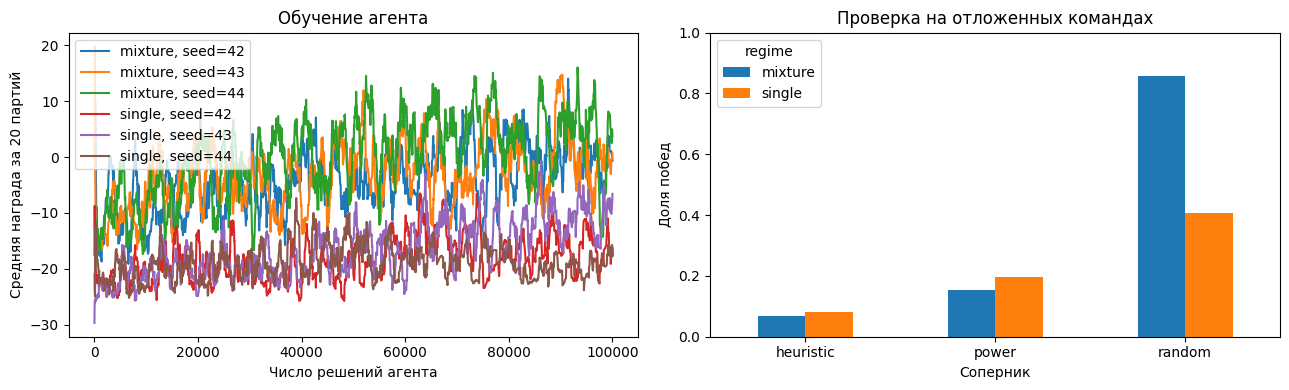

,regime,seed,opponent,battles,wins,losses,draws,cutoffs,win_rate,low95,high95
0,single,42,random,100,17,82,1,0,0.17,0.108935,0.255482
1,single,42,power,100,15,81,1,3,0.15,0.093059,0.232837
2,single,42,heuristic,100,2,96,1,1,0.02,0.005502,0.070013
3,mixture,42,random,100,86,12,0,2,0.86,0.778626,0.914737
4,mixture,42,power,100,10,85,2,3,0.10,0.055229,0.174367
5,mixture,42,heuristic,100,2,94,2,2,0.02,0.005502,0.070013
6,single,43,random,100,64,33,0,3,0.64,0.542352,0.727289
7,single,43,power,100,32,61,4,3,0.32,0.236690,0.416628
8,single,43,heuristic,100,16,82,1,1,0.16,0.100952,0.244204
9,mixture,43,random,100,86,14,0,0,0.86,0.778626,0.914737


,mean_win_rate,std_between_seeds
regime,,
mixture,0.066667,0.050332
single,0.080000,0.072111


In [ ]:
plot_results(training_results, evaluation_summary)


## 15. Пример боя

Сохраняется отдельный бой агента `mixture` против эвристического соперника. В этом примере агент проиграл за 123 решения. Эта партия не включена в итоговые метрики и не описывает поведение всех обученных агентов.


In [ ]:
replay_dir = OUTPUT_DIR / 'replays'
replay_dir.mkdir(exist_ok=True)
seed = config['seeds'][0]
demo = evaluate(agents[('mixture', seed)], pools['test'], 'heuristic',
                seed=76543, n_battles=1, save_replays=str(replay_dir))
display(demo)
replay_files = sorted(replay_dir.glob('*.html'), key=lambda path: path.stat().st_mtime)
if replay_files:
    print('Повтор:', replay_files[-1])
    display(HTML(replay_files[-1].read_text()))
else:
    print('HTML-повтор не создан. Возможно, партия достигла лимита решений.')


,episode,outcome,reward,decisions,battle_tag
0,0,loss,-26.8,123,battle-gen1ou-12166


Повтор: /content/pokemon_rl_results/replays/PokemonEnv taxbq - battle-gen1ou-12166.html


## 16. Сохранение результатов

Сохраняются журналы обучения, результаты боёв, версии библиотек, повторы и веса моделей. Архив содержит таблицы и компактные веса; полные контрольные точки с буфером опыта хранятся отдельно.


In [ ]:
def save_metadata(manifest):
    from importlib.metadata import version
    versions = {name: version(name) for name in ['poke-env', 'torch', 'numpy', 'gymnasium', 'pandas']}
    result = dict(mode=RUN_MODE, settings=config, device=str(DEVICE), versions=versions,
                  showdown=SHOWDOWN_COMMIT, dataset=manifest)
    (OUTPUT_DIR / 'experiment.json').write_text(json.dumps(result, indent=2))
    print('Результаты и контрольные точки:', OUTPUT_DIR)


In [ ]:
save_metadata(dataset_manifest)


Результаты и контрольные точки: /content/pokemon_rl_results


In [ ]:
import zipfile
bundle = ROOT / 'pokemon_rl_results.zip'
with zipfile.ZipFile(bundle, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for path in OUTPUT_DIR.rglob('*'):
        if not path.is_file():
            continue
        if path.suffix in {'.tar', '.gz', '.tmp'} or path.name == 'showdown.log':
            continue
        if path.suffix == '.pt' and not path.name.endswith('.policy.pt'):
            continue
        archive.write(path, path.relative_to(ROOT))
print('Архив результатов:', bundle)
try:
    from google.colab import files
    files.download(str(bundle))
except ImportError:
    print('Архив:', bundle)


Архив результатов: /content/pokemon_rl_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 17. Обсуждение результатов

Средняя доля побед по трём seed:

| Соперник | single | mixture |
|---|---:|---:|
| Случайный | 40,7% | 85,7% |
| Мощные атаки | 19,7% | 15,3% |
| Новый эвристический | 8,0% | 6,7% |

Результаты против нового эвристического соперника:

| Seed | single | mixture |
|---|---:|---:|
| 42 | 2% | 2% |
| 43 | 16% | 6% |
| 44 | 6% | 12% |

Смесь заметно лучше выступает против случайного соперника, который входит в её обучение. Против новой эвристики устойчивого выигрыша нет: при одном seed режимы равны, при другом лучше `single`, при третьем — `mixture`. Разница средних составляет −1,3 процентного пункта для смеси. При трёх seed этого недостаточно для общего вывода о преимуществе одного режима.

По лимиту остановлены 43 из 1800 тестовых партий — около 2,4%. Они учтены в знаменателе доли побед.

### Ограничения

Исследован только формат первого поколения и три программных соперника. Команды частично восстановлены, история боя не моделируется отдельно, а случайность симулятора полностью не фиксируется. В журнале есть предупреждения о распознавании `LIGHT_SCREEN` как `UNKNOWN`; полнота обработки этого эффекта не проверена.

Результаты относятся к выбранному бюджету и данным. Исследование не показывает уровень игры против людей или превосходство над другими алгоритмами RL.


## 18. Остановка симулятора

После сохранения результатов локальный сервер останавливается.


In [ ]:
stop_server(server_process)


## Вывод

Обучены шесть агентов Double DQN и проведено 1800 тестовых боёв. Использован внешний датасет с разделением команд на обучение, валидацию и тест. Реализованы маски действий, сохранение моделей и оценка результатов.

Гипотеза об улучшении игры против нового соперника при обучении на смеси не подтвердилась. Смесь дала 6,7% побед против эвристики, обучение на одном сопернике — 8,0%. При этом смесь лучше справилась со случайным игроком. Таким образом, разнообразие обучающих соперников в данном эксперименте не обеспечило устойчивый перенос стратегии. Дальнейшее развитие — более сильные соперники, учёт истории боя и больший бюджет обучения.


## Источники

- [Metamon Teams — датасет команд](https://huggingface.co/datasets/jakegrigsby/metamon-teams).
- [Pokémon Showdown — симулятор](https://github.com/smogon/pokemon-showdown).
- [poke-env — документация и пример RL](https://poke-env.readthedocs.io/en/stable/examples/reinforcement_learning.html).
- [Grigsby и др., 2025 — обучение агентов Pokémon](https://arxiv.org/abs/2504.04395). Работа объясняет актуальность задачи; её результаты здесь не воспроизводятся.
- [van Hasselt и др., 2015 — Double DQN](https://arxiv.org/abs/1509.06461).
